# Live-cell actin: fluctuation statistics under finite recording time


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。 当前任务只计算观测的中心矩，不恢复潜在发射体对象，已从严格反问题清单排除。

### 观测统计图：当前任务没有潜在物体反演

**观测 y：** 三个完整200帧、450×450强度块intensities，单位ADU。

**实际计算目标：** cumulant2为二阶中心矩(ADU²)，reconstruction实际为四阶中心矩(ADU⁴)，并非发射体位置或密度。solvers.reconstruct只做时间均值和幂次平均；虽然给出荧光前向解释，却未对潜在物体执行逆恢复。

**GT：没有可当恢复物体目标GT的对象。** 独立原程序的统计图仅是数值方法参考，不能充当细胞结构真值。

**过程与实验图：** Notebook主动计算统计图，cell9–13有5组保留PNG，包含观测、统计图及有限帧和亮度敏感性。它们是统计和后处理实验；本轮未重跑。SOFI领域可扩展为物体逆问题，但当前输出契约和实现没有该步骤。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer native-grid fluctuation-statistic images from three real live-cell actin movies. These are blinking-weighted moments/cumulants, not calibrated emitter-density maps.

This review actively reconstructs the three bound real HeLa/Dronpa-C12-actin movies from detector counts. The independent original PySOFI run is a comparison measurement, not molecular ground truth. We select the conventional zero-lag moment-SOFI branch (upstream E1); Fourier interpolation, deconvolution and local display compression in the separate SOFI 2.0 demo are outside this physical output contract.

For detector intensity $F(r,t)$, the temporal mean is $\mu(r)$ and the central moment is $m_n(r)=T^{-1}\sum_t(F(r,t)-\mu(r))^n$. Here $r$ is detector-pixel position, $t$ is frame index, $T=200$ is recording length, and $n$ is order. Each accumulated moment is truncated toward zero to int64 once, as in the original numerical implementation. The recursion $C_n=m_n-\sum_{i=1}^{n-1}\binom{n-1}{i}C_{n-i}m_i$ produces signed cumulants. Brightness is in ADU; $C_n$ has units ADU to power $n$.

Independent blinking makes cumulants add across emitters. For a Gaussian PSF, raising its spatial profile to order $n$ narrows its width by $\sqrt n$, but finite records, shot noise, bleaching and motion limit that gain. These images are blinking-weighted fluctuation contrast rather than calibrated emitter density. The submitted fourth-order image is M4, not C4: short-record cancellation makes C4 noise dominated. M4 retains cross-emitter terms, so the ideal cumulant resolution law does not directly quantify its resolution. Distances remain detector pixels because the bound TIFFs do not establish physical pitch.


## 2. Data

Each selected source block has 200 complete 450 by 450 uint16 frames in ADU. Blocks 1, 10 and 20 retain their original intervals, but absolute timing and physical detector pitch are not established. Independently captured original output is a method reference rather than molecular truth.

The movie blocks are ordered as source blocks 1, 10, and 20. They are separate intervals of the same acquisition; all original spatial pixels and all frames of each block are retained.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| intensities | (1, 3, 200, 450, 450) | uint16 | Recorded fluorescence camera values, ADU; axes batch, block, frame, detector row, detector column |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Label | Dronpa-C12 fused to beta-actin | dimensionless | Reversibly blinking fluorescent protein |
| Sample | Live HeLa cell | dimensionless | Experimental biological specimen |
| Frames per block | 200 | frame | Complete short movie per reconstruction |
| Source block indices | 1, 10, 20 | block | Ordered intervals; no assumption of adjacency |
| Detector field | 450 by 450 | pixel | Full native field, no resize |
| Detector bit depth | 16 | bit | Unsigned intensity storage |
| Coordinates | x is column increasing right; y is row increasing down | pixel | Pixel centers at integer coordinates |
| Temporal lag | 0 | frame | Requested equal-time central moments |
| Spatial boundary | No spatial filtering or wraparound | dimensionless | Statistics evaluated independently at each detector pixel |
| Absolute pixel pitch and inter-block timing | Not deposited in the bound TIFF metadata | unavailable | Report distances in detector pixels; do not infer absolute resolution or dynamics speed |
| Noise calibration | Not supplied | unavailable | Counts are observed ADU, not calibrated photon counts |


## 3. Physics

For detector intensity $F(r,t)$, mean $\mu(r)$ and recording length $T$, moments are $m_n=T^{-1}\sum_t(F-\mu)^n$. Cumulant recursion removes lower-order products under ideal independent blinking. The saved second-order statistic is in ADU squared and fourth moment in ADU to the fourth; the latter deliberately differs from a fourth cumulant.

The observations are three full-field blocks of real HeLa-cell microscopy, with Dronpa-C12 fused to beta-actin. A stationary-emitter approximation applies separately inside each short block:


$$
F(\mathbf r,t)=\sum_{j=1}^{N}\epsilon_j h(\mathbf r-\mathbf r_j)b_j(t)+B(\mathbf r)+\eta(\mathbf r,t).
$$


Here F is the detector reading in analog-to-digital units (ADU), r is a detector-pixel coordinate, t is frame index, N is emitter count, epsilon is the on-state emitter brightness, h is the sampled intensity point-spread function, rj is emitter position, bj is its dimensionless blinking state, B is stationary background, and eta is measurement noise. Subscripts j identify emitters. Blinking between distinct emitters is approximately independent. Temporal fourth-order statistics amplify noise and respond strongly to brightness differences; motion and bleaching violate stationarity.

Recover the spatial second and fourth central moments of the recorded fluorescence at zero time lag, retaining their original detector-count physical scale. These statistics localize independently fluctuating structure; they are not absolute emitter density or a claim of recovered individual molecules. Let mu be the temporal mean and mn the central moment of order n, both computed over all 200 frames in each block. The reference convention truncates each central moment toward zero to an integer ADU power before combining moments. This finite detector-count convention is part of the requested measurement definition. The requested fourth-order image is the central fourth moment, a moment-SOFI statistic that retains cross-emitter terms. The cumulant alternative subtracts 3 times m2 squared when the first central moment is zero, but is unstable for these short recordings and is not the requested output.


## 4. Method

The local finite-record implementation accumulates moments, truncates each once toward zero to int64 as upstream, and derives the selected outputs. No deconvolution, Fourier interpolation or display compression changes the delivered arrays. Root transforms belong only to plots.

Use the conventional moment-SOFI family. Subtract the temporal mean, accumulate moments, and form high-order central-moment images. Moment-SOFI is a stable alternative to subtracting large terms in short-record high-order cumulants, while it retains cross-emitter contributions. For n independent emitters the nth cumulant adds across emitters, and a Gaussian intensity PSF raised to the nth power narrows by the square root of n. This is an ideal cumulant result; mixed terms in a central moment limit that interpretation. Higher order also increases finite-sample uncertainty; comparing orders and recording lengths exposes that tradeoff. Optional display-only contrast transformations must preserve the submitted arrays.


## 5. Results

The active three-block inverse retains all five scientific groups, full-record versus shorter-record recomputations, original/fresh parity and unstable fourth-cumulant alternative. Signed fourth-root maps and negative fractions reveal finite-sample cancellation instead of hiding it.

### Independent numerical comparison and evaluation

The reference below was captured by running the original source on exactly these observations before local extraction. It is identified as an upstream method result; no independently measured specimen truth is available. Every required quantity is evaluated.

### Fresh experiment suite

All alternatives below are actively recomputed with local modules. No archived output is presented as a new alternative. Numerical source values are retained for the displayed experiments.

### Fluctuation orders

All three source blocks are reconstructed. The three display columns use a temporal mean, a square root of the second cumulant, and a fourth root of the fourth central moment. These transformations put display values in ADU, while saved reconstructions retain raw ADU² and ADU⁴. Shared limits within each column permit comparison across blocks; percentile display limits do not alter arrays.

### Filament detail

The fixed center ROI and unnormalized detector-row profiles reveal spatial detail without claiming a calibrated optical resolution. Different orders have different physical meanings and brightness sensitivity, so equal display height does not establish concentration agreement.

### Recording length

Each shorter record is actually recomputed from its first 25, 50, or 100 frames. Error is relative to the 200-frame statistic, not a ground-truth resolution metric. A large high-order change is evidence of limited sampling or dynamics, not a failed reconstruction silently replaced by a cache.

### Dynamics and parity

The temporal traces expose illumination drift and biological dynamics within blocks. Block indices 1, 10, and 20 are source intervals, with no fabricated absolute timing. Original-versus-fresh differences measure numerical extraction fidelity only. The main fourth-order image is the fourth moment M4; the fourth cumulant is independently retained below as an unstable finite-record alternative.

### Moment versus cumulant under short recording

The fourth cumulant is computed from the same freshly reconstructed moments. Its signed fourth-root map and negative fraction make finite-record cancellation visible. The selected moment-SOFI statistic preserves clear filament contrast, while it retains cross-emitter terms and is not presented as a calibrated super-resolution density or proof of absolute resolution.


In [1]:
from pathlib import Path
import os,sys,time,json,platform,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/main.py').exists())
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,figures,export_figures,relative_l2
try:
    import torch
    torch.set_num_threads(1)
except ImportError:
    pass
print('Python',platform.python_version(),'NumPy',np.__version__,'CPU',platform.platform())
data=load_data(root/'data/raw_data.npz')
start=time.perf_counter()
fresh=reconstruct(data)
reconstruction_runtime=time.perf_counter()-start
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
np.savez_compressed(root/'notebooks/reference_outputs/cleaned.npz',**fresh)
print('Fresh complete benchmark reconstruction seconds:',reconstruction_runtime)
print({k:(v.shape,str(v.dtype)) for k,v in fresh.items()})


Python 3.11.11 NumPy 2.4.6 CPU Windows-10-10.0.26200-SP0
Fresh complete benchmark reconstruction seconds: 4.798519900068641
{'cumulant2': ((1, 3, 450, 450), 'float64'), 'reconstruction': ((1, 3, 450, 450), 'float64')}


In [2]:
upstream=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
assert exit_code==0,report
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(report,indent=2))

original_mapping={'cumulant2': 'output_second_moment', 'reconstruction': 'output_fourth_moment'}
print("Direct original-versus-fresh array comparisons:", {k:relative_l2(fresh[k],upstream[v][None]) for k,v in original_mapping.items()})


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "cumulant2_relative_l2": 0.0,
    "reconstruction_relative_l2": 0.0
  },
  "thresholds": {
    "cumulant2_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "reconstruction_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}
Direct original-versus-fresh array comparisons: {'cumulant2': 0.0, 'reconstruction': 0.0}


In [3]:
experiment_start=time.perf_counter()
experiments=run_experiments(data,fresh)
experiment_runtime=time.perf_counter()-experiment_start
np.savez_compressed(root/'notebooks/reference_outputs/experiments.npz',**experiments)
plots=figures(data,fresh,upstream,experiments)
plt.close('all')  # Keep figure objects; scientific sections display each plate once.
print('Additional experiment seconds:',experiment_runtime)
print({k:v.shape for k,v in experiments.items()})


Additional experiment seconds: 4.385199900018051
{'frames': (4,), 'length_errors': (4, 2), 'short_reconstruction': (1, 3, 450, 450), 'mean_images': (3, 450, 450), 'block_trace': (3, 200), 'negative_fraction': (3,)}


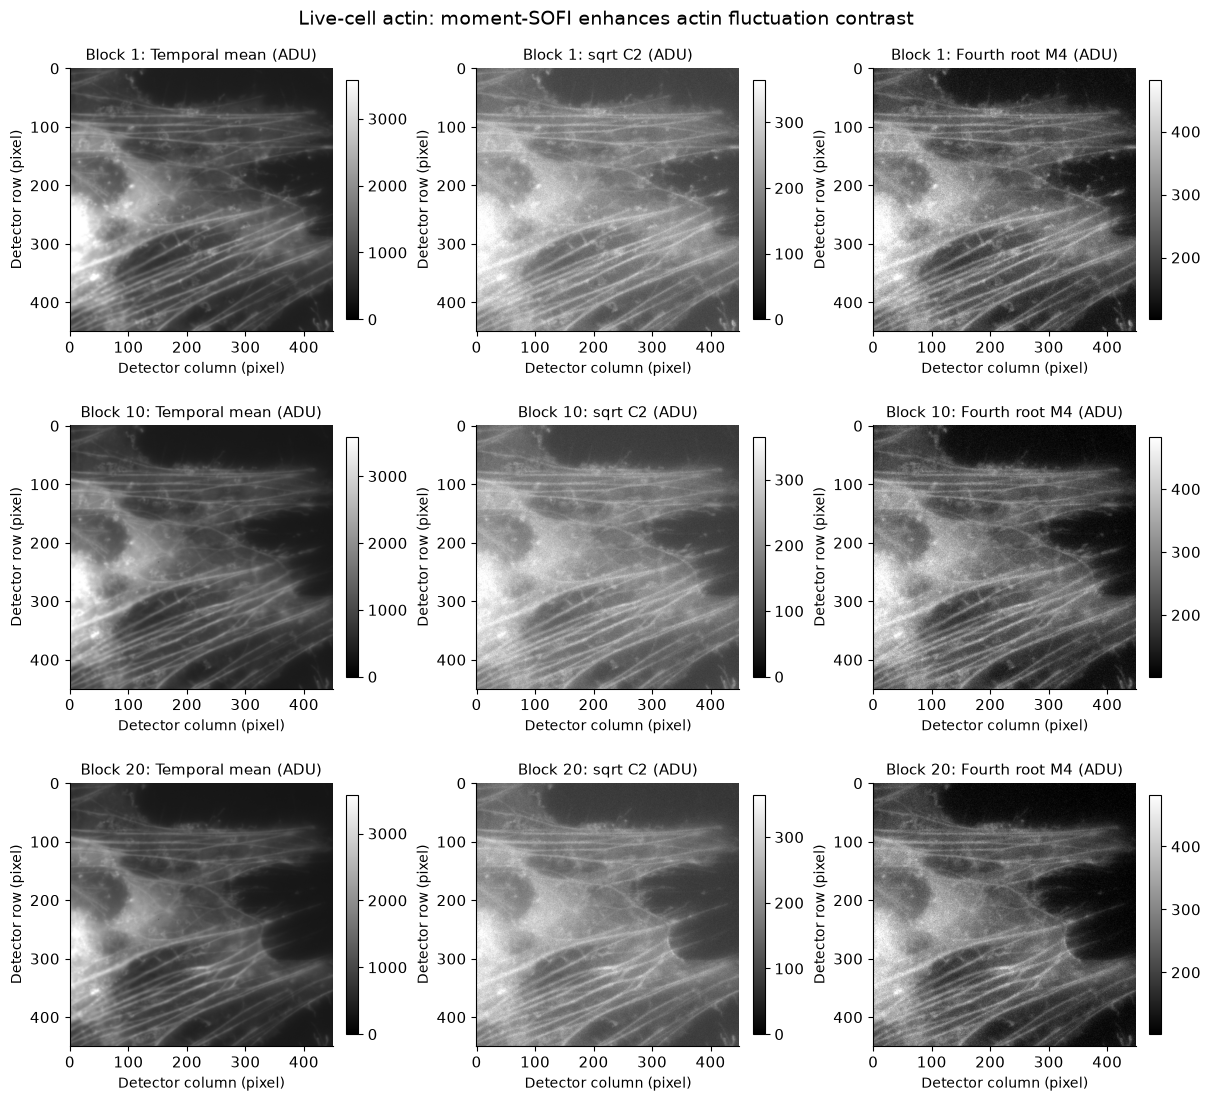

In [4]:
display(plots['01_fluctuation_orders'])
plt.close(plots['01_fluctuation_orders'])

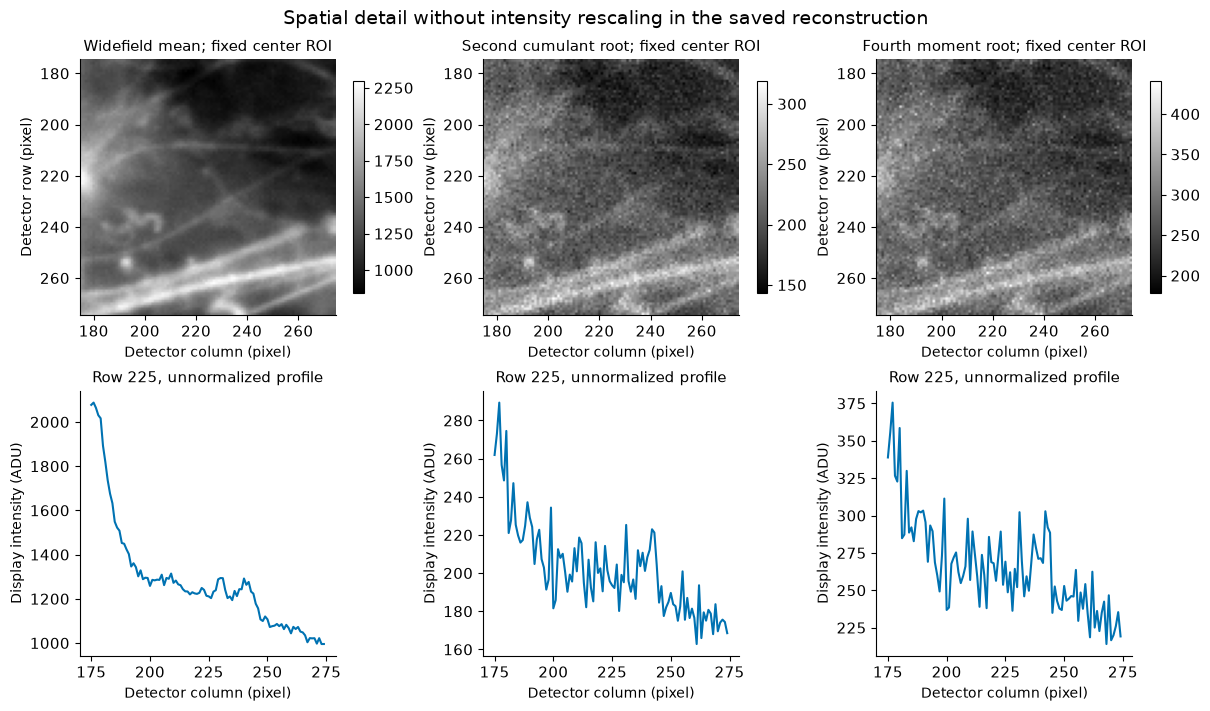

In [5]:
display(plots['02_filament_detail'])
plt.close(plots['02_filament_detail'])

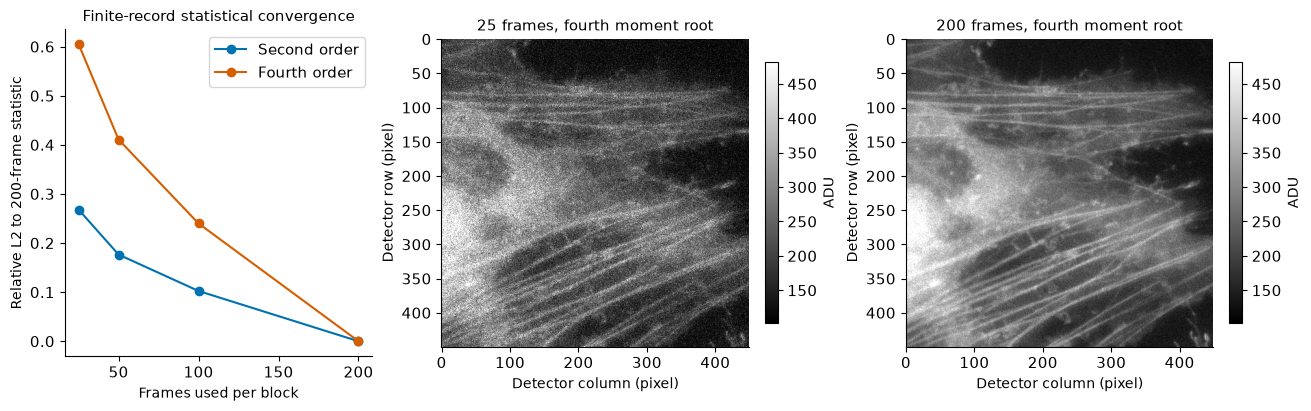

In [6]:
display(plots['03_recording_length'])
plt.close(plots['03_recording_length'])

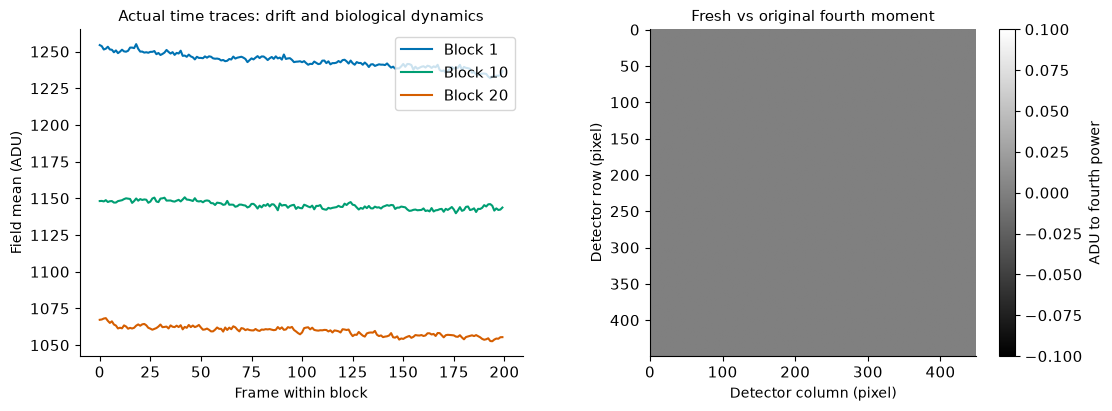

In [7]:
display(plots['04_dynamics_and_parity'])
plt.close(plots['04_dynamics_and_parity'])

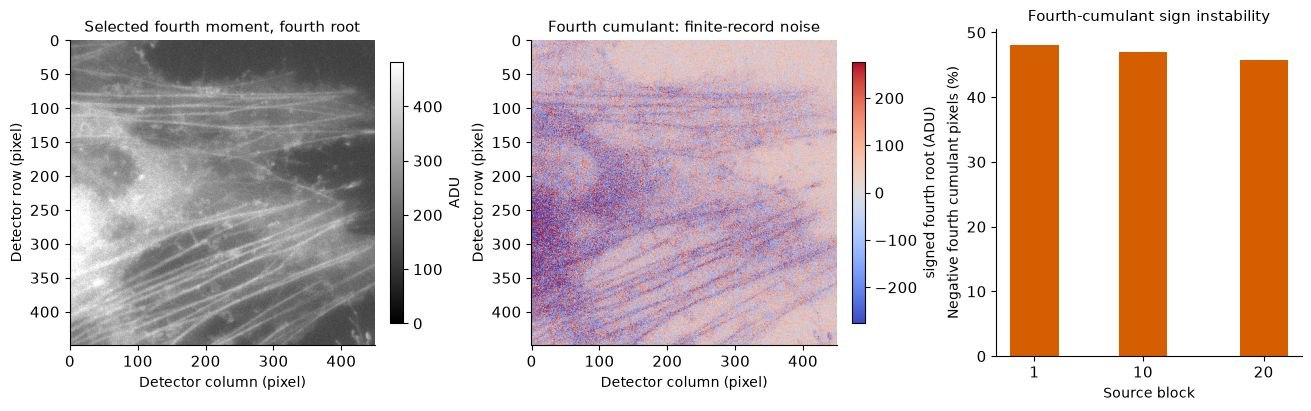

In [8]:
display(plots['05_cumulant_sampling_limitation'])
plt.close(plots['05_cumulant_sampling_limitation'])

In [9]:
measurement={'reconstruction_runtime_s':reconstruction_runtime,'experiment_runtime_s':experiment_runtime,
             'python':platform.python_version(),'numpy':np.__version__,'metrics':report['metrics']}
(root/'notebooks/reference_outputs/measurement.json').write_text(json.dumps(measurement,indent=2),encoding='utf8')
# An optional maintainer-owned export directory keeps publication figures out of the task runtime.
if os.environ.get('IMAGING_EXPORT_DIR'):
    values={**{k:v for k,v in fresh.items()},**{'experiment_'+k:v for k,v in experiments.items()}}
    export_figures(plots,Path(os.environ['IMAGING_EXPORT_DIR']),values)
print(json.dumps(measurement,indent=2))


{
  "reconstruction_runtime_s": 4.798519900068641,
  "experiment_runtime_s": 4.385199900018051,
  "python": "3.11.11",
  "numpy": "2.4.6",
  "metrics": {
    "cumulant2_relative_l2": 0.0,
    "reconstruction_relative_l2": 0.0
  }
}


## 6. Conclusion

The comparisons support faithful moment-SOFI extraction and expose recording-length sensitivity. The Gaussian cumulant square-root-order narrowing law does not directly quantify fourth-moment resolution; motion, bleaching and shot noise prevent calibrated super-resolution-density claims.

### Conclusion and review record

Fresh original-method agreement validates the local mathematical extraction on these observations. The actual observation and calibration experiments above delimit the scientific interpretation; agreement with a standard reconstruction does not establish hidden physical truth. The notebook keeps physical failures and uncertain estimates visible.
